# Import Library Torch dan Proses Pengecekan Device
---
Baris ini digunakan untuk memanggil *library* PyTorch dan memverifikasi apakah environment Google Colab saat ini berjalan menggunakan akselerasi GPU NVIDIA (CUDA) atau hanya mengandalkan CPU dengan nilai *boolean*. Jika, nilainya `True` maka GPU NVIDIA, sedangkan nilai `false` berarti CPU.

In [ ]:
import torch

print("CUDA Status :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name :", torch.cuda.get_device_name(0))
else:
    print("Perangkat masih menggunakan CPU")

CUDA Status : True
Device Name : Tesla T4


# Import Library
---
Baris ini berisikan library yang digunakan selama proses pembuatan model AI, mulai dari `os` agar Python dapat berinteraksi dengan sistem operasi. Kemudian, `pandas` untuk manipulasi dan analisis data, `numpy` untuk komputasi numerikal, `matplotlib.pyplot` dan `seaborn` untuk membuat visualisasi data berupa grafik garis, diagram batang, dan lain-lain.

Lalu ada `cv2` untuk untuk mengolah gambar dan video, `re` untuk melacak teks, serta `shutil` untuk melakukan copy-paste, memindahkan, atau menghapus file dan folder dengan mudah.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import re
import shutil

### Pengambilan dataset tingkat kematangan kakao (*cocoa ripeness*) dari Kaggle menggunakan kagglehub, yang kemudian disalin ke folder proyek lokal menggunakan shutil agar siap untuk diolah.
---

In [ ]:
import kagglehub

temp_path = kagglehub.dataset_download("juanfelipeheredia/cocoa-ripeness-dataset-tcs-01")

target_path = "./data/cocoa-ripeness"

shutil.copytree(temp_path, target_path, dirs_exist_ok=True)

print("Dataset berhasil disimpan di:", target_path)

Using Colab cache for faster access to the 'cocoa-ripeness-dataset-tcs-01' dataset.
Dataset berhasil disimpan di: ./data/cocoa-ripeness


### Pengelompokan dataset gambar ke dalam folder terpisah berdasarkan kategori kematangannya (Immature, Mature, Overmature) dengan mendeteksi kode huruf pada nama file menggunakan Regex, lalu menyalin file tersebut ke foldernya masing-masing menggunakan shutil.
---

In [ ]:
source_dir = f"{target_path}"
output_dir = "./dataset_grouped"

label_map = {
    'I': 'Immature',
    'M': 'Mature',
    'S': 'Overmature'
}

count = 0

for root, dirs, files in os.walk(source_dir):
    for filename in files:
        if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
            # Ekstrak huruf prefix
            match = re.match(r"^([a-zA-Z]+)", filename)

            if match:
                code = match.group(1).upper()
                label_name = label_map.get(code, "Unknown")

                # Buat folder target berdasarkan label
                target_folder = os.path.join(output_dir, label_name)
                os.makedirs(target_folder, exist_ok=True)

                # Salin gambar dari lokasi aslinya (root) ke folder tujuan
                src_file = os.path.join(root, filename)
                dst_file = os.path.join(target_folder, filename)

                shutil.copy(src_file, dst_file)
                count += 1

print("Pengelompokkan folder selesai!")

Pengelompokkan folder selesai!


### Mengubah daftar lokasi file gambar (filepath) dan labelnya (Immature, Mature, Overmature) yang sudah dikelompokkan sebelumnya ke dalam format tabel data dan menampilkan visualisasi perbandingan jumlah data untuk masing-masing kategori kematangan dalam bentuk diagram batang.
---

--- Contoh Baris Data ---


,filename,filepath,label
467,I179.jpg,./dataset_grouped/Immature/I179.jpg,Immature
33,S5.jpg,./dataset_grouped/Overmature/S5.jpg,Overmature
131,S125.jpg,./dataset_grouped/Overmature/S125.jpg,Overmature
72,S42.jpg,./dataset_grouped/Overmature/S42.jpg,Overmature
78,S100.jpg,./dataset_grouped/Overmature/S100.jpg,Overmature
113,S26.jpg,./dataset_grouped/Overmature/S26.jpg,Overmature
274,I195.jpg,./dataset_grouped/Immature/I195.jpg,Immature
185,M33.jpg,./dataset_grouped/Mature/M33.jpg,Mature
261,I173.jpg,./dataset_grouped/Immature/I173.jpg,Immature
9,S80.jpg,./dataset_grouped/Overmature/S80.jpg,Overmature


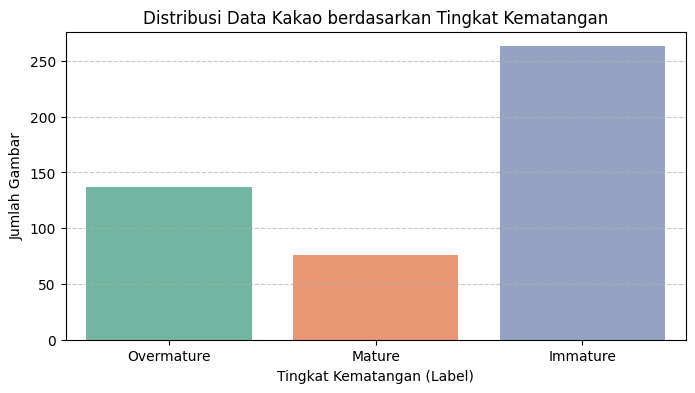

In [ ]:
data = []

for label_name in os.listdir(output_dir):
    label_path = os.path.join(output_dir, label_name)

    if os.path.isdir(label_path):
        for filename in os.listdir(label_path):
            if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                filepath = os.path.join(label_path, filename)

                data.append({
                    'filename': filename,
                    'filepath': filepath,
                    'label': label_name
                })

df = pd.DataFrame(data)

print("--- Contoh Baris Data ---")
display(df.sample(10, random_state=42))

# jumlah gambar per kategori/label
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='label', hue='label', palette='Set2', legend=False)
plt.title('Distribusi Data Kakao berdasarkan Tingkat Kematangan')
plt.xlabel('Tingkat Kematangan (Label)')
plt.ylabel('Jumlah Gambar')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Membagi *dataset* menjadi bagian utama, `train`(60%) sebagai bahan model belajar, `validation`(20%) untuk bahan evaluasi model ketika proses pembelajaran sehingga model mengetahui apakah ia sudah belajar dengan benar dan mencegah terjadinya overfitting, serta `test`(20%) sebagai bahan ujian akhir yang isinya data baru dan relevan di dunia nyata.
---

In [ ]:
from sklearn.model_selection import train_test_split

# Lokasi folder asal dan folder tujuan pemisahan
source_grouped_dir = "./dataset_grouped"
output_split_dir = "./dataset_split"

# Kumpulkan semua path file dan label dari folder dataset_grouped
data_paths = []
for label_name in os.listdir(source_grouped_dir):
    label_path = os.path.join(source_grouped_dir, label_name)
    if os.path.isdir(label_path):
        for filename in os.listdir(label_path):
            if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                filepath = os.path.join(label_path, filename)
                data_paths.append((filepath, label_name))

df_paths = pd.DataFrame(data_paths, columns=['filepath', 'label'])

# Stratified Split
train_val_df, test_df = train_test_split(
    df_paths,
    test_size=0.20,
    stratify=df_paths['label'],
    random_state=42
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.25,
    stratify=train_val_df['label'],
    random_state=42
)

# Fungsi untuk menyalin file ke struktur folder baru
def copy_files(dataframe, split_name):
    for _, row in dataframe.iterrows():
        src = row['filepath']
        label = row['label']
        filename = os.path.basename(src)

        dst_dir = os.path.join(output_split_dir, split_name, label)
        os.makedirs(dst_dir, exist_ok=True)

        dst = os.path.join(dst_dir, filename)
        shutil.copy(src, dst)

copy_files(train_df, 'train')
copy_files(val_df, 'val')
copy_files(test_df, 'test')

print("Pemisahan dataset selesai!\n")

summary_df = pd.DataFrame({
    'Train (60%)': train_df['label'].value_counts(),
    'Validation (20%)': val_df['label'].value_counts(),
    'Test (20%)': test_df['label'].value_counts()
})
display(summary_df)

Pemisahan dataset selesai!



,Train (60%),Validation (20%),Test (20%)
label,,,
Immature,157,53,53
Overmature,82,27,28
Mature,46,15,15


### Melakukan preprocessing dataset menggunakan modul transforms untuk augmentasi data latih guna meningkatkan variasi dan mencegah overfitting. Selain itu, Weighted Random Sampler untuk menangani ketidakseimbangan jumlah data antar kelas.
---

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms

# augmentasi acak agar model belajar variasi posisi, rotasi, & warna
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Data Validation & Test
val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(root='./dataset_split/train', transform=train_transforms)
val_dataset   = datasets.ImageFolder(root='./dataset_split/val', transform=val_test_transforms)
test_dataset  = datasets.ImageFolder(root='./dataset_split/test', transform=val_test_transforms)

targets = train_dataset.targets

# Hitung jumlah sampel di setiap kelas
class_sample_count = np.bincount(targets)
print(f"Jumlah sampel per kelas di Training: {class_sample_count}")

# Hitung bobot per kelas
class_weights = 1.0 / class_sample_count
print(f"Bobot per kelas: {class_weights}")

sample_weights = [class_weights[t] for t in targets]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True
)

# DataLoader
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2
)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("\nDataLoader berhasil dibuat dan siap digunakan untuk training!")

Jumlah sampel per kelas di Training: [157  46  82]
Bobot per kelas: [0.00636943 0.02173913 0.01219512]

DataLoader berhasil dibuat dan siap digunakan untuk training!


### Mengecek isi dari satu kelompok data (*batch*) pertama untuk menghitung jumlah masing-masing kategori kematangan kakao, guna memastikan data sudah dikelompokkan dengan benar dan siap dipelajari oleh model.
---

In [ ]:
images, labels = next(iter(train_loader))

unique, counts = np.unique(labels.numpy(), return_counts=True)
class_names = train_dataset.classes

print("Distribusi kelas dalam 1 Batch Training:")
for idx, count in zip(unique, counts):
    print(f"- {class_names[idx]}: {count} gambar")

Distribusi kelas dalam 1 Batch Training:
- Immature: 18 gambar
- Mature: 8 gambar
- Overmature: 6 gambar


# Uji Coba Model 1: ResNet18


In [ ]:
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

# Load Pre-trained Model (ResNet18)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 3)

model = model.to(device)

# Loss Function & Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training Loop
EPOCHS = 20

# Tempat penyimpanan checkpoint
checkpoint_dir = "./checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)
best_model_path = os.path.join(checkpoint_dir, "best_resnet18_cocoa.pth")

best_val_acc = 0.0

for epoch in range(EPOCHS):
    # PHASE TRAINING
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data)
        total_train += labels.size(0)

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train.double() / total_train

    # PHASE VALIDATION
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels.data)
            total_val += labels.size(0)

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val.double() / total_val

    # Cetak Progress
    print(f"Epoch [{epoch+1}/{EPOCHS}] "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} "
          f"| Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': best_val_acc,
            'val_loss': epoch_val_loss
        }, best_model_path)
        print(f"  --> Checkpoint disimpan! (Val Acc Meningkat: {best_val_acc:.4f})")

print("\nPelatihan Selesai!")

Menggunakan device: cuda
Epoch [1/20] Train Loss: 0.9586 | Train Acc: 0.6175 | Val Loss: 15.3135 | Val Acc: 0.2842
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.2842)
Epoch [2/20] Train Loss: 0.4385 | Train Acc: 0.8000 | Val Loss: 10.7163 | Val Acc: 0.2947
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.2947)
Epoch [3/20] Train Loss: 0.2860 | Train Acc: 0.8772 | Val Loss: 0.2692 | Val Acc: 0.9158
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.9158)
Epoch [4/20] Train Loss: 0.3070 | Train Acc: 0.8807 | Val Loss: 4.7271 | Val Acc: 0.3895
Epoch [5/20] Train Loss: 0.3919 | Train Acc: 0.8386 | Val Loss: 0.4668 | Val Acc: 0.8632
Epoch [6/20] Train Loss: 0.2590 | Train Acc: 0.8982 | Val Loss: 0.2136 | Val Acc: 0.9158
Epoch [7/20] Train Loss: 0.2787 | Train Acc: 0.8807 | Val Loss: 0.1797 | Val Acc: 0.9158
Epoch [8/20] Train Loss: 0.2358 | Train Acc: 0.9158 | Val Loss: 0.3722 | Val Acc: 0.8421
Epoch [9/20] Train Loss: 0.3065 | Train Acc: 0.8632 | Val Loss: 0.0862 | Val Acc: 0.9789
  --> C

# Proses Menyimpan Hasil Train Ke Drive

In [ ]:
from google.colab import drive
import shutil

drive.mount('/content/drive')

src = './checkpoints/best_resnet18_cocoa.pth'
dst = '/content/drive/MyDrive/Matkul AI/Cocoa/Checkpoints'

shutil.copy(src, dst)
print("Berhasil disimpan ke Google Drive!")

Mounted at /content/drive
Berhasil disimpan ke Google Drive!


### Melakukan evaluasi performa model dengan memuat model terbaik hasil pelatihan, melakukan prediksi pada data uji, serta memvisualisasikan hasil evaluasinya ke dalam bentuk Classification Report, Confusion Matrix, dan grafik batang untuk menganalisis akurasi tebakan model pada setiap kelas kematangan kakao.
---

Model berhasil dimuat dari Epoch 9 (Val Acc: 0.9789)

              CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Immature     1.0000    0.9623    0.9808        53
      Mature     0.7000    0.9333    0.8000        15
  Overmature     0.9600    0.8571    0.9057        28

    accuracy                         0.9271        96
   macro avg     0.8867    0.9176    0.8955        96
weighted avg     0.9415    0.9271    0.9306        96



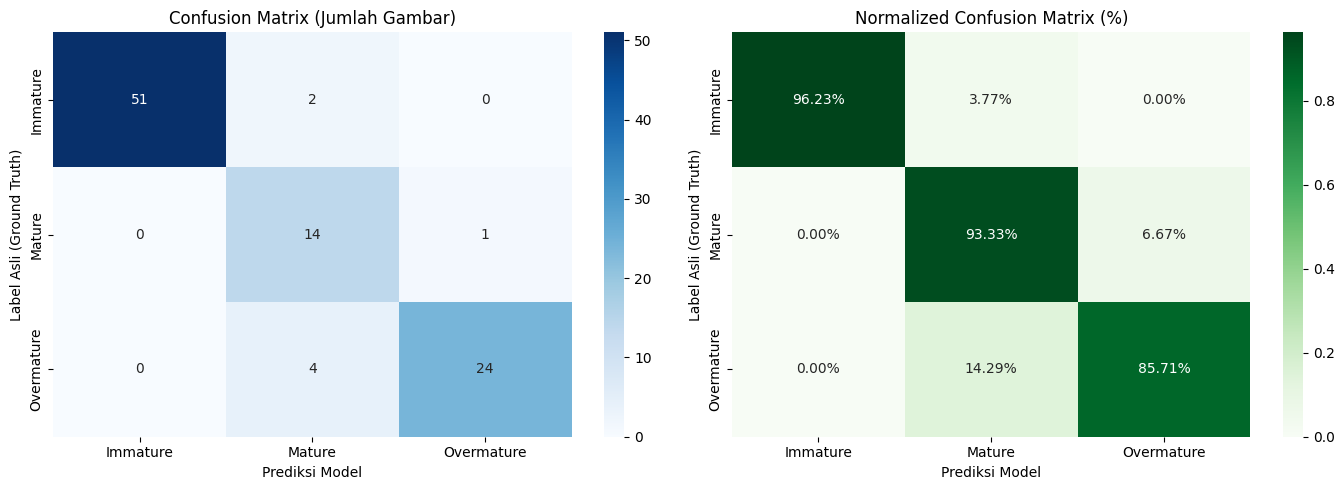

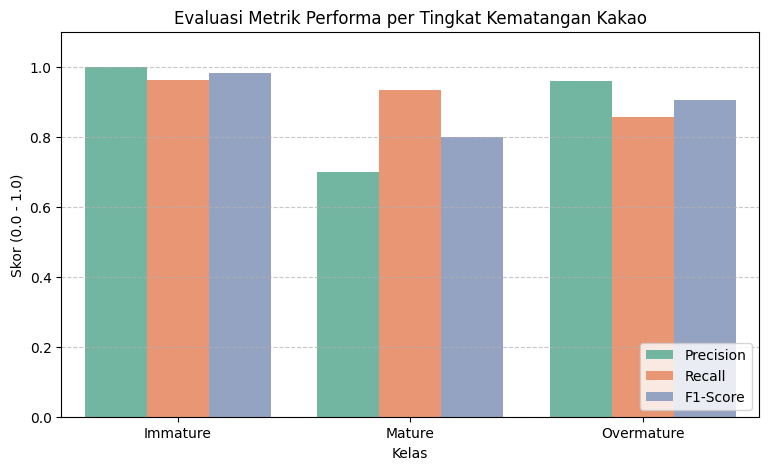

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score, precision_recall_fscore_support

# Load Checkpoint Model Terbaik
checkpoint_path = './checkpoints/best_resnet18_cocoa.pth'
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)
model.eval()

print(f"Model berhasil dimuat dari Epoch {checkpoint['epoch']} (Val Acc: {checkpoint['val_acc']:.4f})")

# Prediksi pada Test Set
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = test_dataset.classes  # ['Immature', 'Mature', 'Overmature']

# CLASSIFICATION REPORT
print("\n" + "="*50)
print("              CLASSIFICATION REPORT")
print("="*50)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# CONFUSION MATRIX (Normalized & Raw)
cm = confusion_matrix(all_labels, all_preds)
cm_norm = confusion_matrix(all_labels, all_preds, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriks 1: Jumlah Asli (Counts)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix (Jumlah Gambar)')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Label Asli (Ground Truth)')

# Matriks 2: Persentase (Normalized)
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Normalized Confusion Matrix (%)')
axes[1].set_xlabel('Prediksi Model')
axes[1].set_ylabel('Label Asli (Ground Truth)')

plt.tight_layout()
plt.show()

# CHART PERFORMA METRIK PER KELAS (F1-Score, Precision, Recall)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average=None)

metrics_df = {
    'Kelas': class_names * 3,
    'Nilai': np.concatenate([precision, recall, f1]),
    'Metrik': ['Precision']*len(class_names) + ['Recall']*len(class_names) + ['F1-Score']*len(class_names)
}

import pandas as pd
df_metrics = pd.DataFrame(metrics_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=df_metrics, x='Kelas', y='Nilai', hue='Metrik', palette='Set2')
plt.title('Evaluasi Metrik Performa per Tingkat Kematangan Kakao')
plt.ylim(0, 1.1)
plt.ylabel('Skor (0.0 - 1.0)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()

### Uji Coba Model Alternatif: EfficientNet-B0
---
Bagian ini menambahkan model EfficientNet-B0 sebagai pembanding ResNet18.
Semua variabel pakai suffix `_effnet` supaya tidak menimpa variabel ResNet18.

In [ ]:
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

# Load Pre-trained Model (EfficientNet-B0)
model_effnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

# Ganti classifier head sesuai jumlah kelas (Immature, Mature, Overmature)
num_features_effnet = model_effnet.classifier[1].in_features
model_effnet.classifier[1] = nn.Linear(num_features_effnet, 3)

model_effnet = model_effnet.to(device)

# Loss Function & Optimizer (terpisah dari punya ResNet18)
criterion_effnet = nn.CrossEntropyLoss()
optimizer_effnet = optim.Adam(model_effnet.parameters(), lr=0.001)

# Training Loop
EPOCHS_EFFNET = 20

checkpoint_dir = "./checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)
best_model_path_effnet = os.path.join(checkpoint_dir, "best_efficientnet_b0_cocoa.pth")

best_val_acc_effnet = 0.0

for epoch in range(EPOCHS_EFFNET):
    # PHASE TRAINING
    model_effnet.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model_effnet(images)
        loss = criterion_effnet(outputs, labels)

        optimizer_effnet.zero_grad()
        loss.backward()
        optimizer_effnet.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data)
        total_train += labels.size(0)

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train.double() / total_train

    # PHASE VALIDATION
    model_effnet.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_effnet(images)
            loss = criterion_effnet(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels.data)
            total_val += labels.size(0)

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val.double() / total_val

    print(f"[EfficientNet-B0] Epoch [{epoch+1}/{EPOCHS_EFFNET}] "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} "
          f"| Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")

    if epoch_val_acc > best_val_acc_effnet:
        best_val_acc_effnet = epoch_val_acc
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model_effnet.state_dict(),
            'optimizer_state_dict': optimizer_effnet.state_dict(),
            'val_acc': best_val_acc_effnet,
            'val_loss': epoch_val_loss
        }, best_model_path_effnet)
        print(f"  --> Checkpoint disimpan! (Val Acc Meningkat: {best_val_acc_effnet:.4f})")

print("\nPelatihan EfficientNet-B0 Selesai!")

Menggunakan device: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 162MB/s]


[EfficientNet-B0] Epoch [1/20] Train Loss: 0.6021 | Train Acc: 0.7333 | Val Loss: 0.5904 | Val Acc: 0.8421
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.8421)
[EfficientNet-B0] Epoch [2/20] Train Loss: 0.2818 | Train Acc: 0.8912 | Val Loss: 0.4411 | Val Acc: 0.9053
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.9053)
[EfficientNet-B0] Epoch [3/20] Train Loss: 0.2027 | Train Acc: 0.9228 | Val Loss: 0.3447 | Val Acc: 0.9579
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.9579)
[EfficientNet-B0] Epoch [4/20] Train Loss: 0.1862 | Train Acc: 0.9263 | Val Loss: 0.4138 | Val Acc: 0.9263
[EfficientNet-B0] Epoch [5/20] Train Loss: 0.1164 | Train Acc: 0.9789 | Val Loss: 0.2601 | Val Acc: 0.9368
[EfficientNet-B0] Epoch [6/20] Train Loss: 0.0941 | Train Acc: 0.9789 | Val Loss: 0.2174 | Val Acc: 0.9474
[EfficientNet-B0] Epoch [7/20] Train Loss: 0.0761 | Train Acc: 0.9684 | Val Loss: 0.4727 | Val Acc: 0.8947
[EfficientNet-B0] Epoch [8/20] Train Loss: 0.0914 | Train Acc: 0.9754 | Val Loss: 0.27

# Proses Menyimpan Hasil Train Ke Drive

In [ ]:
from google.colab import drive
import shutil
import os

try:
    # Menjalankan mount dengan force_remount untuk menyegarkan sesi
    drive.mount('/content/drive', force_remount=True)

    src_effnet = './checkpoints/best_efficientnet_b0_cocoa.pth'
    dst_dir = '/content/drive/MyDrive/Matkul AI/Cocoa/Checkpoints'

    # Memastikan folder tujuan ada di Drive
    if not os.path.exists(dst_dir):
        os.makedirs(dst_dir, exist_ok=True)

    dst_effnet = os.path.join(dst_dir, 'best_efficientnet_b0_cocoa.pth')

    if os.path.exists(src_effnet):
        shutil.copy(src_effnet, dst_effnet)
        print("✅ Berhasil! Checkpoint EfficientNet-B0 disimpan ke Google Drive.")
    else:
        print(f"⚠️ Error: File {src_effnet} tidak ditemukan di sistem lokal.")

except Exception as e:
    print(f"❌ Gagal menyambungkan ke Drive: {e}")
    print("Tips: Pastikan cookie pihak ketiga diizinkan di browser Anda dan pop-up tidak diblokir.")

Mounted at /content/drive
✅ Berhasil! Checkpoint EfficientNet-B0 disimpan ke Google Drive.


### Melakukan evaluasi performa model dengan memuat model terbaik hasil pelatihan, melakukan prediksi pada data uji, serta memvisualisasikan hasil evaluasinya ke dalam bentuk Classification Report, Confusion Matrix, dan grafik batang untuk menganalisis akurasi tebakan model pada setiap kelas kematangan kakao.
---

Model EfficientNet-B0 berhasil dimuat dari Epoch 19 (Val Acc: 0.9684)

       CLASSIFICATION REPORT (EfficientNet-B0)
              precision    recall  f1-score   support

    Immature     0.9464    1.0000    0.9725        53
      Mature     0.8000    0.8000    0.8000        15
  Overmature     1.0000    0.8929    0.9434        28

    accuracy                         0.9375        96
   macro avg     0.9155    0.8976    0.9053        96
weighted avg     0.9392    0.9375    0.9370        96



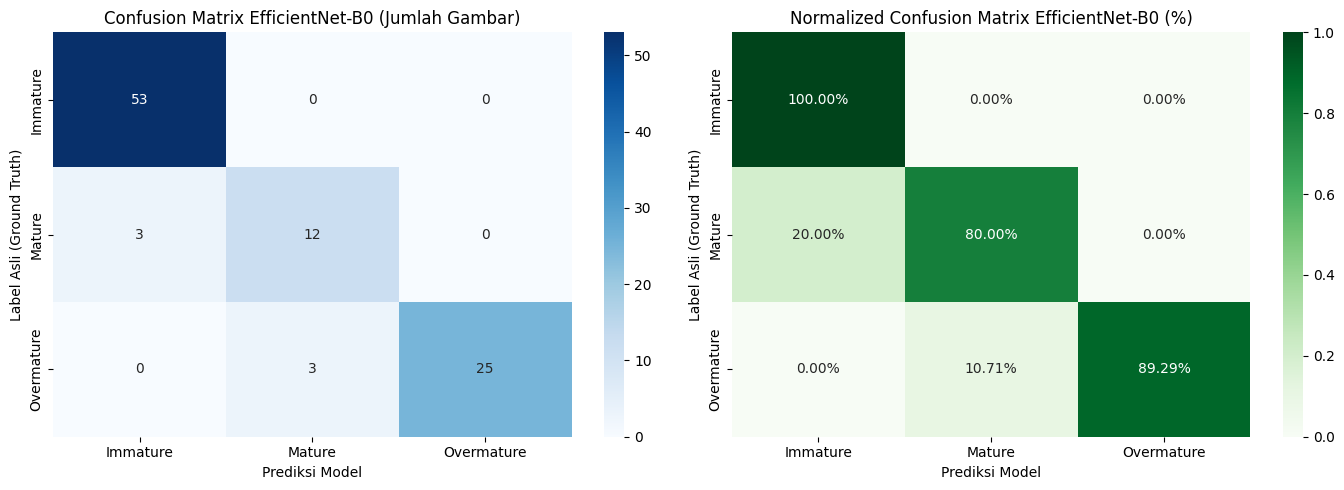

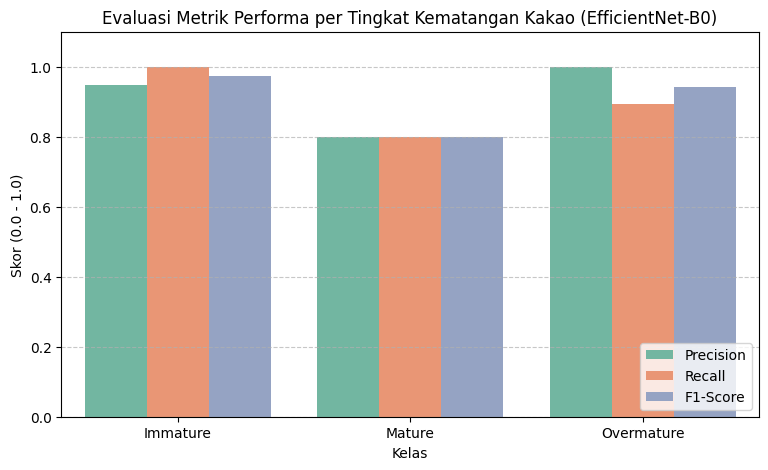

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score, precision_recall_fscore_support

checkpoint_path_effnet = './checkpoints/best_efficientnet_b0_cocoa.pth'
checkpoint_effnet = torch.load(checkpoint_path_effnet)
model_effnet.load_state_dict(checkpoint_effnet['model_state_dict'])
model_effnet.to(device)
model_effnet.eval()

print(f"Model EfficientNet-B0 berhasil dimuat dari Epoch {checkpoint_effnet['epoch']} (Val Acc: {checkpoint_effnet['val_acc']:.4f})")

all_preds_effnet = []
all_labels_effnet = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_effnet(images)
        _, preds = torch.max(outputs, 1)

        all_preds_effnet.extend(preds.cpu().numpy())
        all_labels_effnet.extend(labels.numpy())

class_names = test_dataset.classes

print("\n" + "="*50)
print("       CLASSIFICATION REPORT (EfficientNet-B0)")
print("="*50)
print(classification_report(all_labels_effnet, all_preds_effnet, target_names=class_names, digits=4))

cm_effnet = confusion_matrix(all_labels_effnet, all_preds_effnet)
cm_norm_effnet = confusion_matrix(all_labels_effnet, all_preds_effnet, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm_effnet, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix EfficientNet-B0 (Jumlah Gambar)')
axes[0].set_xlabel('Prediksi Model')
axes[0].set_ylabel('Label Asli (Ground Truth)')

sns.heatmap(cm_norm_effnet, annot=True, fmt='.2%', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Normalized Confusion Matrix EfficientNet-B0 (%)')
axes[1].set_xlabel('Prediksi Model')
axes[1].set_ylabel('Label Asli (Ground Truth)')

plt.tight_layout()
plt.show()

precision_effnet, recall_effnet, f1_effnet, _ = precision_recall_fscore_support(all_labels_effnet, all_preds_effnet, average=None)

metrics_df_effnet = {
    'Kelas': class_names * 3,
    'Nilai': np.concatenate([precision_effnet, recall_effnet, f1_effnet]),
    'Metrik': ['Precision']*len(class_names) + ['Recall']*len(class_names) + ['F1-Score']*len(class_names)
}

df_metrics_effnet = pd.DataFrame(metrics_df_effnet)

plt.figure(figsize=(9, 5))
sns.barplot(data=df_metrics_effnet, x='Kelas', y='Nilai', hue='Metrik', palette='Set2')
plt.title('Evaluasi Metrik Performa per Tingkat Kematangan Kakao (EfficientNet-B0)')
plt.ylim(0, 1.1)
plt.ylabel('Skor (0.0 - 1.0)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()

# REVISI: Training Model pada Dataset Hasil Augmentasi (Balanced)
---
Sesuai dengan masukan dosen pengajar, kedua model (ResNet18 dan EfficientNet-B0) telah kami **latih ulang menggunakan dataset train hasil oversampling/augmentasi** sehingga jumlah gambar tiap kelas seimbang. Sebelumnya, model dilatih pada data asli yang tidak seimbang (Immature 157, Overmature 82, Mature 46) dan hanya dibantu `WeightedRandomSampler`.

**Yang berubah pada revisi ini**

| Aspek | Sebelumnya | Revisi |
|---|---|---|
| Data train | Data asli (tidak seimbang) | Data asli + gambar hasil augmentasi (`aug_*.jpg`) → semua kelas sama banyak |
| Penyeimbang kelas | `WeightedRandomSampler` (oversampling di memori) | Oversampling fisik ke folder `./dataset_augmented/train` → `shuffle=True` biasa |
| Validation & Test | Data asli | **Tetap data asli** (tidak diaugmentasi, agar evaluasi jujur & tanpa data leakage) |
| Hyperparameter | Adam, lr=0.001, 20 epoch, batch 32, simpan checkpoint dengan Val Acc terbaik | **Sama persis** |
| Checkpoint | `best_*_cocoa.pth` | `best_*_cocoa_augmented.pth` (file lama tidak tertimpa) |

## Cell yang perlu dijalankan
**Jika runtime Colab baru atau sudah di-restart** (jalankan berurutan dari atas):
1. `Import Library Torch dan Proses Pengecekan Device` (cek GPU)
2. `Import Library`
3. Cell download dataset Kaggle (`kagglehub`)
4. Cell pengelompokan dataset (`dataset_grouped`)
5. Cell pembagian `train / val / test` (`dataset_split`)
6. **Semua cell di bagian REVISI, dari Langkah 1 sampai Langkah 12**

**Jika runtime masih hidup** dan folder `./dataset_split` sudah ada, cukup jalankan bagian REVISI.

Jika sebelumnya (Cell lama) sudah dijalankan pada sesi yang sama, hasilnya otomatis dipakai di Langkah 12 sebagai pembanding sebelum vs sesudah.

### Langkah 1 - Oversampling dengan augmentasi offline (hanya data train)
---
Kelas dengan jumlah gambar paling banyak pada data train (Immature = 157) dijadikan target. Kelas Mature dan Overmature ditambah gambar hasil augmentasi (flip, rotasi/geser/zoom, dan perubahan warna) sampai jumlahnya sama dengan target. Gambar hasil augmentasi disimpan **secara fisik** ke `./dataset_augmented/train` dengan awalan nama `aug_`, dan seluruh proses dicatat di `augmentation_manifest.csv`. Data validation dan test **tidak** diaugmentasi.

In [ ]:
import os, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

# ---------------- Konfigurasi ----------------
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

SPLIT_DIR          = "./dataset_split"
ORIGINAL_TRAIN_DIR = os.path.join(SPLIT_DIR, "train")   # train ASLI (tidak seimbang)
VAL_DIR            = os.path.join(SPLIT_DIR, "val")     # val ASLI
TEST_DIR           = os.path.join(SPLIT_DIR, "test")    # test ASLI

AUG_ROOT           = "./dataset_augmented"
AUG_TRAIN_DIR      = os.path.join(AUG_ROOT, "train")    # train HASIL AUGMENTASI (seimbang)
AUG_PREFIX         = "aug_"                              # penanda nama file hasil augmentasi
IMG_EXT            = ('.png', '.jpg', '.jpeg')

def list_images(folder):
    return sorted(f for f in os.listdir(folder) if f.lower().endswith(IMG_EXT))

def is_aug(filename):
    return filename.startswith(AUG_PREFIX)

assert os.path.isdir(ORIGINAL_TRAIN_DIR), (
    "Folder ./dataset_split/train belum ada. Jalankan dulu cell pembagian dataset train/val/test."
)

# ---------------- Transformasi augmentasi (PIL -> PIL) ----------------
offline_augment = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomAffine(degrees=30, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
])

# ---------------- Bangun dataset train yang seimbang ----------------
if os.path.exists(AUG_ROOT):
    shutil.rmtree(AUG_ROOT)          # reset supaya tidak menumpuk jika cell dijalankan ulang

classes = sorted(d for d in os.listdir(ORIGINAL_TRAIN_DIR)
                 if os.path.isdir(os.path.join(ORIGINAL_TRAIN_DIR, d)))
original_files = {c: list_images(os.path.join(ORIGINAL_TRAIN_DIR, c)) for c in classes}
counts_before  = {c: len(v) for c, v in original_files.items()}
TARGET_PER_CLASS = max(counts_before.values())

print("Jumlah train ASLI      :", counts_before)
print("Target tiap kelas      :", TARGET_PER_CLASS)
print("-" * 60)

manifest = []
for c in classes:
    dst_dir = os.path.join(AUG_TRAIN_DIR, c)
    os.makedirs(dst_dir, exist_ok=True)

    # 1) salin dulu semua gambar ASLI kelas ini
    for fname in original_files[c]:
        shutil.copy2(os.path.join(ORIGINAL_TRAIN_DIR, c, fname), os.path.join(dst_dir, fname))

    # 2) tambah gambar augmentasi sampai jumlahnya = target
    need = TARGET_PER_CLASS - len(original_files[c])
    if need <= 0:
        print(f"{c:<11}: sudah terbanyak, tidak perlu augmentasi")
        continue

    order = original_files[c].copy()
    random.shuffle(order)            # sumber dipilih bergiliran -> merata ke semua gambar asli
    for i in range(need):
        src_name = order[i % len(order)]
        img = Image.open(os.path.join(ORIGINAL_TRAIN_DIR, c, src_name)).convert("RGB")
        aug_img = offline_augment(img)

        new_name = f"{AUG_PREFIX}{os.path.splitext(src_name)[0]}_{i+1:03d}.jpg"
        aug_img.save(os.path.join(dst_dir, new_name), quality=95)
        manifest.append({"aug_file": new_name, "source_file": src_name, "label": c})

    print(f"{c:<11}: {len(original_files[c])} asli + {need} augmentasi = {TARGET_PER_CLASS}")

manifest_df = pd.DataFrame(manifest)
manifest_path = os.path.join(AUG_ROOT, "augmentation_manifest.csv")
manifest_df.to_csv(manifest_path, index=False)

print("-" * 60)
print(f"Total gambar augmentasi dibuat : {len(manifest_df)}")
print(f"Dataset hasil augmentasi       : {AUG_TRAIN_DIR}")
print(f"Catatan proses (manifest)      : {manifest_path}")

Jumlah train ASLI      : {'Immature': 157, 'Mature': 46, 'Overmature': 82}
Target tiap kelas      : 157
------------------------------------------------------------
Immature   : sudah terbanyak, tidak perlu augmentasi
Mature     : 46 asli + 111 augmentasi = 157
Overmature : 82 asli + 75 augmentasi = 157
------------------------------------------------------------
Total gambar augmentasi dibuat : 186
Dataset hasil augmentasi       : ./dataset_augmented/train
Catatan proses (manifest)      : ./dataset_augmented/augmentation_manifest.csv


### Langkah 2 - Validasi bahwa dataset train sudah seimbang & bebas data leakage
---
Cell ini membuktikan bahwa (1) jumlah gambar tiap kelas sudah sama, (2) gambar hasil augmentasi benar-benar ada (berawalan `aug_`) dan sesuai catatan manifest, (3) validation & test tidak mengandung gambar augmentasi, dan (4) tidak ada gambar train yang sama dengan validation/test. Jika ada yang gagal, cell akan berhenti dengan pesan error.

,Train ASLI (sebelum),Original di folder augmented,Hasil augmentasi (aug_),Train SESUDAH,Val (asli),Test (asli)
Kelas,,,,,,
Immature,157,157,0,157,53,53
Mature,46,46,111,157,15,15
Overmature,82,82,75,157,27,28



HASIL VALIDASI
------------------------------------------------------------
✅ Semua kelas pada train memiliki jumlah gambar SAMA (seimbang)
✅ Jumlah data original di folder augmented = jumlah train asli
✅ Jumlah file 'aug_' di folder = jumlah baris di manifest
✅ Semua gambar augmentasi bersumber dari data TRAIN
✅ Validation & Test bersih dari gambar augmentasi (tidak ada 'aug_')
✅ Tidak ada data leakage (file train tidak ada di val/test)
------------------------------------------------------------
🎉 Semua validasi lolos. Setiap kelas berisi 157 gambar pada data train.


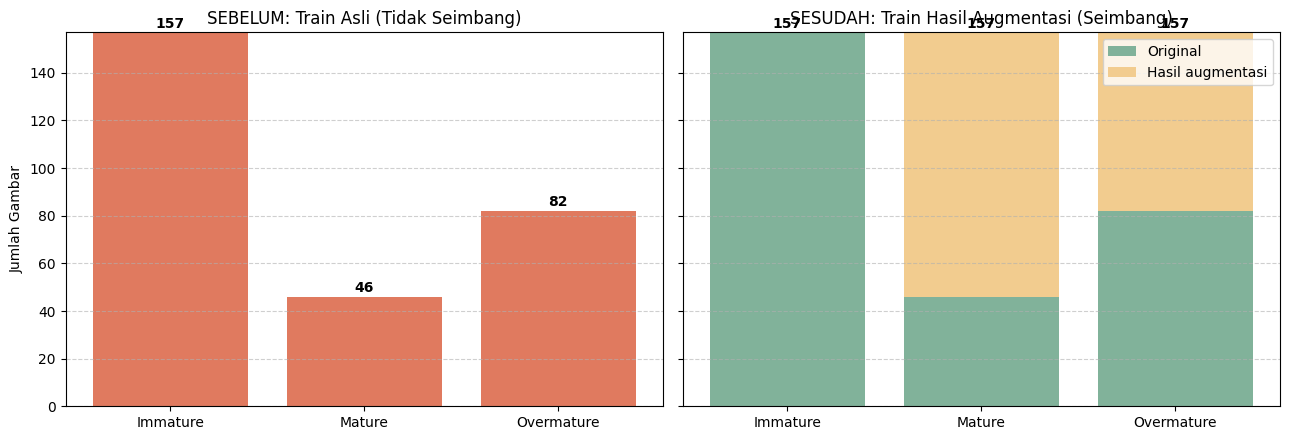

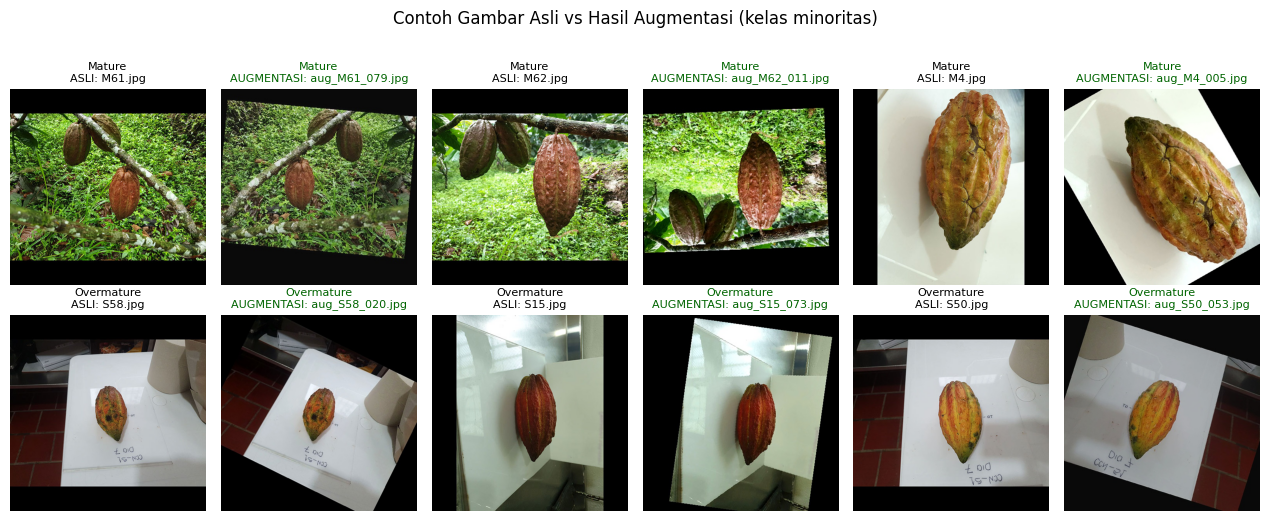

In [ ]:
# ---------------- Tabel perbandingan sebelum vs sesudah ----------------
rows = []
for c in classes:
    files_aug_dir = list_images(os.path.join(AUG_TRAIN_DIR, c))
    n_aug  = sum(is_aug(f) for f in files_aug_dir)
    n_orig = len(files_aug_dir) - n_aug
    rows.append({
        "Kelas": c,
        "Train ASLI (sebelum)": counts_before[c],
        "Original di folder augmented": n_orig,
        "Hasil augmentasi (aug_)": n_aug,
        "Train SESUDAH": n_orig + n_aug,
        "Val (asli)": len(list_images(os.path.join(VAL_DIR, c))),
        "Test (asli)": len(list_images(os.path.join(TEST_DIR, c))),
    })
df_check = pd.DataFrame(rows).set_index("Kelas")
display(df_check)

# ---------------- Pemeriksaan otomatis ----------------
results = []
def check(desc, cond):
    results.append(bool(cond))
    print(("✅ " if cond else "❌ ") + desc)

train_names_all  = {f for c in classes for f in list_images(os.path.join(AUG_TRAIN_DIR, c))}
train_names_orig = {f for f in train_names_all if not is_aug(f)}
valtest_names    = {f for d in (VAL_DIR, TEST_DIR) for c in classes for f in list_images(os.path.join(d, c))}

print("\nHASIL VALIDASI")
print("-" * 60)
check("Semua kelas pada train memiliki jumlah gambar SAMA (seimbang)",
      df_check["Train SESUDAH"].nunique() == 1)
check("Jumlah data original di folder augmented = jumlah train asli",
      (df_check["Original di folder augmented"] == df_check["Train ASLI (sebelum)"]).all())
check("Jumlah file 'aug_' di folder = jumlah baris di manifest",
      df_check["Hasil augmentasi (aug_)"].sum() == len(manifest_df))
check("Semua gambar augmentasi bersumber dari data TRAIN",
      set(manifest_df["source_file"]).issubset(train_names_orig))
check("Validation & Test bersih dari gambar augmentasi (tidak ada 'aug_')",
      not any(is_aug(f) for f in valtest_names))
check("Tidak ada data leakage (file train tidak ada di val/test)",
      train_names_all.isdisjoint(valtest_names))
print("-" * 60)
assert all(results), "Ada validasi yang gagal, periksa hasil di atas."
print(f"🎉 Semua validasi lolos. Setiap kelas berisi {int(df_check['Train SESUDAH'].iloc[0])} gambar pada data train.")

# ---------------- Visualisasi jumlah data sebelum vs sesudah ----------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

axes[0].bar(df_check.index, df_check["Train ASLI (sebelum)"], color="#E07A5F")
axes[0].set_title("SEBELUM: Train Asli (Tidak Seimbang)")
axes[0].set_ylabel("Jumlah Gambar")
for i, v in enumerate(df_check["Train ASLI (sebelum)"]):
    axes[0].text(i, v + 2, str(v), ha="center", fontweight="bold")

axes[1].bar(df_check.index, df_check["Original di folder augmented"], color="#81B29A", label="Original")
axes[1].bar(df_check.index, df_check["Hasil augmentasi (aug_)"],
            bottom=df_check["Original di folder augmented"], color="#F2CC8F", label="Hasil augmentasi")
axes[1].set_title("SESUDAH: Train Hasil Augmentasi (Seimbang)")
for i, v in enumerate(df_check["Train SESUDAH"]):
    axes[1].text(i, v + 2, str(v), ha="center", fontweight="bold")
axes[1].legend()

for ax in axes:
    ax.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# ---------------- Contoh gambar: original vs hasil augmentasi ----------------
minority = [c for c in classes if (manifest_df["label"] == c).any()]
n_pairs = 3
fig, axes = plt.subplots(len(minority), n_pairs * 2, figsize=(3 * n_pairs * 2 * 0.6 + 2, 2.6 * len(minority)))
axes = np.atleast_2d(axes)
rng = np.random.RandomState(SEED)
for r, c in enumerate(minority):
    sample = manifest_df[manifest_df["label"] == c].sample(n_pairs, random_state=rng)
    for k, (_, row) in enumerate(sample.iterrows()):
        axes[r, 2*k].imshow(Image.open(os.path.join(ORIGINAL_TRAIN_DIR, c, row["source_file"])))
        axes[r, 2*k].set_title(f"{c}\nASLI: {row['source_file']}", fontsize=8)
        axes[r, 2*k+1].imshow(Image.open(os.path.join(AUG_TRAIN_DIR, c, row["aug_file"])))
        axes[r, 2*k+1].set_title(f"{c}\nAUGMENTASI: {row['aug_file']}", fontsize=8, color="darkgreen")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Contoh Gambar Asli vs Hasil Augmentasi (kelas minoritas)", y=1.02)
plt.tight_layout()
plt.show()

### Langkah 3 - DataLoader untuk dataset hasil augmentasi
---
`train_loader_aug` membaca folder `./dataset_augmented/train`. Karena kelasnya sudah seimbang, **`WeightedRandomSampler` tidak dipakai lagi** (cukup `shuffle=True`). Validation dan test tetap memakai data asli di `./dataset_split`.

Augmentasi acak saat training (`USE_ONLINE_AUG`) dimatikan secara default supaya model benar-benar belajar dari gambar yang sudah diaugmentasi secara fisik. Dijadiin `True` kalau ingin memberi variasi tambahan setiap epoch.

Di akhir cell terdapat fungsi validasi `verify_training_dataset()` yang juga akan dipanggil otomatis di awal setiap proses training.

In [ ]:
USE_ONLINE_AUG = False     # True = tambah augmentasi acak lagi saat training (seperti versi lama)
BATCH_SIZE = 32
NORM_MEAN, NORM_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

base_tf = [transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(NORM_MEAN, NORM_STD)]

if USE_ONLINE_AUG:
    train_tf_aug = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(degrees=30),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(NORM_MEAN, NORM_STD),
    ])
else:
    train_tf_aug = transforms.Compose(base_tf)
val_test_tf_aug = transforms.Compose(base_tf)

train_dataset_aug = datasets.ImageFolder(AUG_TRAIN_DIR, transform=train_tf_aug)   # <-- DATASET HASIL AUGMENTASI
val_dataset_aug   = datasets.ImageFolder(VAL_DIR,  transform=val_test_tf_aug)      # asli
test_dataset_aug  = datasets.ImageFolder(TEST_DIR, transform=val_test_tf_aug)      # asli

assert train_dataset_aug.class_to_idx == val_dataset_aug.class_to_idx == test_dataset_aug.class_to_idx, \
    "Urutan kelas train/val/test tidak sama!"
class_names_aug = train_dataset_aug.classes
NUM_CLASSES = len(class_names_aug)

train_loader_aug = DataLoader(train_dataset_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader_aug   = DataLoader(val_dataset_aug,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader_aug  = DataLoader(test_dataset_aug,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)


def verify_training_dataset(loader):
    """Memastikan loader training memang membaca dataset hasil augmentasi & seimbang."""
    ds = loader.dataset
    counts = np.bincount(ds.targets, minlength=len(ds.classes))
    aug_counts = np.zeros(len(ds.classes), dtype=int)
    for path, t in ds.samples:
        if is_aug(os.path.basename(path)):
            aug_counts[t] += 1

    ok_folder  = os.path.abspath(ds.root) == os.path.abspath(AUG_TRAIN_DIR)
    ok_aug     = int(aug_counts.sum()) > 0
    ok_balance = len(set(counts.tolist())) == 1
    ok_sampler = not isinstance(loader.sampler, torch.utils.data.WeightedRandomSampler)

    print("=" * 66)
    print("VALIDASI DATASET TRAINING")
    print("=" * 66)
    print(f"Folder train : {os.path.abspath(ds.root)}")
    print(f"Sampler      : {type(loader.sampler).__name__}")
    print(f"{'Kelas':<12}{'Total':>8}{'Original':>10}{'Augmentasi (aug_)':>20}")
    for i, c in enumerate(ds.classes):
        print(f"{c:<12}{counts[i]:>8}{counts[i]-aug_counts[i]:>10}{aug_counts[i]:>20}")
    print("-" * 66)
    print(("✅" if ok_folder  else "❌"), "Membaca folder dataset_augmented/train")
    print(("✅" if ok_aug     else "❌"), f"Berisi gambar hasil augmentasi ({int(aug_counts.sum())} file aug_)")
    print(("✅" if ok_balance else "❌"), "Jumlah tiap kelas seimbang")
    print(("✅" if ok_sampler else "❌"), "Tidak memakai WeightedRandomSampler")
    print("=" * 66)
    assert ok_folder and ok_aug and ok_balance and ok_sampler, \
        "Dataset training BUKAN dataset augmentasi yang seimbang. Jalankan ulang Langkah 1-3."

    return {
        "train_dir": os.path.abspath(ds.root),
        "class_counts": {c: int(counts[i]) for i, c in enumerate(ds.classes)},
        "n_augmented": int(aug_counts.sum()),
        "n_original": int(counts.sum() - aug_counts.sum()),
    }

train_ds_info = verify_training_dataset(train_loader_aug)

# Distribusi kelas pada 1 batch (kira-kira seimbang karena data sudah seimbang + shuffle)
images, labels = next(iter(train_loader_aug))
unique, cnts = np.unique(labels.numpy(), return_counts=True)
print("\nDistribusi kelas dalam 1 Batch Training (acak):")
for idx, n in zip(unique, cnts):
    print(f"- {class_names_aug[idx]}: {n} gambar")
print(f"\nVal : {len(val_dataset_aug)} gambar (asli) | Test: {len(test_dataset_aug)} gambar (asli)")

VALIDASI DATASET TRAINING
Folder train : /content/dataset_augmented/train
Sampler      : RandomSampler
Kelas          Total  Original   Augmentasi (aug_)
Immature         157       157                   0
Mature           157        46                 111
Overmature       157        82                  75
------------------------------------------------------------------
✅ Membaca folder dataset_augmented/train
✅ Berisi gambar hasil augmentasi (186 file aug_)
✅ Jumlah tiap kelas seimbang
✅ Tidak memakai WeightedRandomSampler

Distribusi kelas dalam 1 Batch Training (acak):
- Immature: 5 gambar
- Mature: 8 gambar
- Overmature: 19 gambar

Val : 95 gambar (asli) | Test: 96 gambar (asli)


### Langkah 4 - Fungsi bantu untuk training, evaluasi, dan penyimpanan
---
Logika training sama seperti kode sebelumnya (Adam, lr=0.001, 20 epoch, batch 32, simpan checkpoint saat Val Acc terbaik), hanya dirapikan menjadi fungsi agar bisa dipakai oleh ResNet18 maupun EfficientNet-B0 tanpa menyalin kode. Setiap checkpoint kini juga menyimpan **metadata dataset** (`dataset_type = augmented_balanced`, jumlah gambar per kelas, jumlah gambar `aug_`) sebagai bukti model dilatih pada dataset hasil augmentasi.

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support, accuracy_score, f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

EPOCHS = 20
LR = 0.001
CHECKPOINT_DIR = "./checkpoints"
DRIVE_CKPT_DIR = "/content/drive/MyDrive/Matkul AI/Cocoa/Checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)


def train_model(model, model_name, ckpt_path, epochs=EPOCHS, lr=LR):
    # Validasi: pastikan loader training memang dataset hasil augmentasi
    ds_info = verify_training_dataset(train_loader_aug)
    print(f"\n[{model_name}] TRAINING DIMULAI pada dataset AUGMENTASI "
          f"({ds_info['n_original']} original + {ds_info['n_augmented']} augmentasi)\n")

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0

    for epoch in range(epochs):
        # ---------- PHASE TRAINING ----------
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        for images, labels in train_loader_aug:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_train += torch.sum(preds == labels.data).item()
            total_train += labels.size(0)

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = correct_train / total_train

        # ---------- PHASE VALIDATION ----------
        model.eval()
        val_loss, correct_val, total_val = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader_aug:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct_val += torch.sum(preds == labels.data).item()
                total_val += labels.size(0)

        epoch_val_loss = val_loss / total_val
        epoch_val_acc = correct_val / total_val

        history["train_loss"].append(epoch_train_loss); history["train_acc"].append(epoch_train_acc)
        history["val_loss"].append(epoch_val_loss);     history["val_acc"].append(epoch_val_acc)

        print(f"[{model_name} | AUG] Epoch [{epoch+1}/{epochs}] "
              f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} "
              f"| Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")

        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_acc": best_val_acc,
                "val_loss": epoch_val_loss,
                # ---- bukti dataset yang dipakai ----
                "model_name": model_name,
                "dataset_type": "augmented_balanced",
                "train_dir": ds_info["train_dir"],
                "train_class_counts": ds_info["class_counts"],
                "n_augmented_images": ds_info["n_augmented"],
                "n_original_images": ds_info["n_original"],
                "class_names": list(class_names_aug),
            }, ckpt_path)
            print(f"  --> Checkpoint disimpan! (Val Acc Meningkat: {best_val_acc:.4f})")

    print(f"\nPelatihan {model_name} pada dataset augmentasi selesai! Best Val Acc: {best_val_acc:.4f}")
    return model, history


def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="Train Loss"); axes[0].plot(history["val_loss"], label="Val Loss")
    axes[0].set_title(f"Loss - {model_name} (dataset augmentasi)"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(history["train_acc"], label="Train Acc"); axes[1].plot(history["val_acc"], label="Val Acc")
    axes[1].set_title(f"Accuracy - {model_name} (dataset augmentasi)"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    for ax in axes: ax.grid(linestyle="--", alpha=0.6)
    plt.tight_layout(); plt.show()


def evaluate_model(model, ckpt_path, model_name):
    ckpt = torch.load(ckpt_path, map_location=device)

    # Validasi: checkpoint harus berasal dari training pada dataset augmentasi
    print("=" * 66)
    print(f"VALIDASI CHECKPOINT: {os.path.basename(ckpt_path)}")
    print("=" * 66)
    print("Tipe dataset train  :", ckpt.get("dataset_type"))
    print("Folder train        :", ckpt.get("train_dir"))
    print("Jumlah per kelas    :", ckpt.get("train_class_counts"))
    print("Gambar original     :", ckpt.get("n_original_images"))
    print("Gambar augmentasi   :", ckpt.get("n_augmented_images"))
    assert ckpt.get("dataset_type") == "augmented_balanced", "Checkpoint ini BUKAN hasil training dataset augmentasi!"
    print("✅ Model ini dilatih pada dataset hasil augmentasi (balanced)")
    print("=" * 66)

    model.load_state_dict(ckpt["model_state_dict"])
    model.to(device).eval()
    print(f"Model {model_name} dimuat dari Epoch {ckpt['epoch']} (Val Acc: {ckpt['val_acc']:.4f})")

    y_pred, y_true = [], []
    with torch.no_grad():
        for images, labels in test_loader_aug:
            outputs = model(images.to(device))
            y_pred.extend(torch.max(outputs, 1)[1].cpu().numpy())
            y_true.extend(labels.numpy())

    print("\n" + "=" * 60)
    print(f"   CLASSIFICATION REPORT ({model_name} - Dataset Augmentasi)")
    print("=" * 60)
    print(classification_report(y_true, y_pred, target_names=class_names_aug, digits=4, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = confusion_matrix(y_true, y_pred, normalize="true")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_aug, yticklabels=class_names_aug, ax=axes[0])
    axes[0].set_title(f"Confusion Matrix {model_name} - Augmented (Jumlah Gambar)")
    sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Greens", xticklabels=class_names_aug, yticklabels=class_names_aug, ax=axes[1])
    axes[1].set_title(f"Normalized Confusion Matrix {model_name} - Augmented (%)")
    for ax in axes:
        ax.set_xlabel("Prediksi Model"); ax.set_ylabel("Label Asli (Ground Truth)")
    plt.tight_layout(); plt.show()

    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)
    k = len(class_names_aug)
    df_m = pd.DataFrame({
        "Kelas": class_names_aug * 3,
        "Nilai": np.concatenate([precision, recall, f1]),
        "Metrik": ["Precision"] * k + ["Recall"] * k + ["F1-Score"] * k,
    })
    plt.figure(figsize=(9, 5))
    sns.barplot(data=df_m, x="Kelas", y="Nilai", hue="Metrik", palette="Set2")
    plt.title(f"Evaluasi Metrik per Tingkat Kematangan Kakao ({model_name} - Augmented)")
    plt.ylim(0, 1.1); plt.ylabel("Skor (0.0 - 1.0)"); plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.legend(loc="lower right"); plt.show()

    return {"y_true": np.array(y_true), "y_pred": np.array(y_pred)}


def save_to_drive(local_path, drive_dir=DRIVE_CKPT_DIR):
    from google.colab import drive
    try:
        drive.mount("/content/drive")
        os.makedirs(drive_dir, exist_ok=True)
        dst = os.path.join(drive_dir, os.path.basename(local_path))
        if os.path.exists(local_path):
            shutil.copy(local_path, dst)
            print(f"✅ Berhasil! {os.path.basename(local_path)} disimpan ke Google Drive:\n   {dst}")
        else:
            print(f"⚠️ File {local_path} tidak ditemukan. Jalankan cell training terlebih dahulu.")
    except Exception as e:
        print(f"❌ Gagal menyimpan ke Drive: {e}")
        print("Tips: pastikan cookie pihak ketiga diizinkan di browser dan pop-up tidak diblokir.")

print("Fungsi bantu siap dipakai.")

Menggunakan device: cuda
Fungsi bantu siap dipakai.


### Langkah 5 - Training ulang Model 1: ResNet18 (dataset augmentasi)
---
Arsitektur, optimizer, learning rate, jumlah epoch, dan batch size sama dengan percobaan sebelumnya. Yang berbeda hanya data train-nya. Sebelum training dimulai akan tercetak tabel **VALIDASI DATASET TRAINING** yang menunjukkan bahwa data berasal dari `dataset_augmented/train`.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


VALIDASI DATASET TRAINING
Folder train : /content/dataset_augmented/train
Sampler      : RandomSampler
Kelas          Total  Original   Augmentasi (aug_)
Immature         157       157                   0
Mature           157        46                 111
Overmature       157        82                  75
------------------------------------------------------------------
✅ Membaca folder dataset_augmented/train
✅ Berisi gambar hasil augmentasi (186 file aug_)
✅ Jumlah tiap kelas seimbang
✅ Tidak memakai WeightedRandomSampler

[ResNet18] TRAINING DIMULAI pada dataset AUGMENTASI (285 original + 186 augmentasi)

[ResNet18 | AUG] Epoch [1/20] Train Loss: 0.6510 | Train Acc: 0.7240 | Val Loss: 0.4544 | Val Acc: 0.8000
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.8000)
[ResNet18 | AUG] Epoch [2/20] Train Loss: 0.2843 | Train Acc: 0.8896 | Val Loss: 0.3956 | Val Acc: 0.9053
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.9053)
[ResNet18 | AUG] Epoch [3/20] Train Loss: 0.1771 | Train Acc:

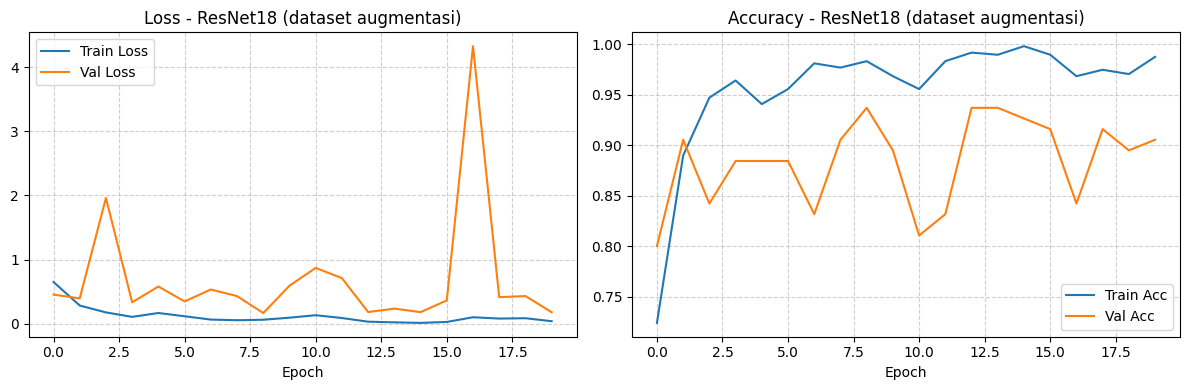

In [ ]:
set_seed()

model_resnet_aug = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_resnet_aug.fc = nn.Linear(model_resnet_aug.fc.in_features, NUM_CLASSES)

best_path_resnet_aug = os.path.join(CHECKPOINT_DIR, "best_resnet18_cocoa_augmented.pth")

model_resnet_aug, history_resnet_aug = train_model(
    model_resnet_aug, "ResNet18", best_path_resnet_aug, epochs=EPOCHS, lr=LR
)
plot_history(history_resnet_aug, "ResNet18")

### Langkah 6 - Simpan checkpoint ResNet18 (augmented) ke Google Drive
---
Disimpan dengan nama baru `best_resnet18_cocoa_augmented.pth`, sehingga checkpoint lama tidak tertimpa.

In [ ]:
save_to_drive(best_path_resnet_aug)

Mounted at /content/drive
✅ Berhasil! best_resnet18_cocoa_augmented.pth disimpan ke Google Drive:
   /content/drive/MyDrive/Matkul AI/Cocoa/Checkpoints/best_resnet18_cocoa_augmented.pth


### Langkah 7 - Evaluasi ResNet18 (augmented) pada data test asli
---
Sebelum evaluasi, metadata checkpoint dicetak dan divalidasi untuk memastikan model dilatih pada dataset hasil augmentasi. Data test tetap data asli yang tidak diaugmentasi.

VALIDASI CHECKPOINT: best_resnet18_cocoa_augmented.pth
Tipe dataset train  : augmented_balanced
Folder train        : /content/dataset_augmented/train
Jumlah per kelas    : {'Immature': 157, 'Mature': 157, 'Overmature': 157}
Gambar original     : 285
Gambar augmentasi   : 186
✅ Model ini dilatih pada dataset hasil augmentasi (balanced)
Model ResNet18 dimuat dari Epoch 9 (Val Acc: 0.9368)

   CLASSIFICATION REPORT (ResNet18 - Dataset Augmentasi)
              precision    recall  f1-score   support

    Immature     0.9636    1.0000    0.9815        53
      Mature     0.8000    0.8000    0.8000        15
  Overmature     0.9615    0.8929    0.9259        28

    accuracy                         0.9375        96
   macro avg     0.9084    0.8976    0.9025        96
weighted avg     0.9375    0.9375    0.9369        96



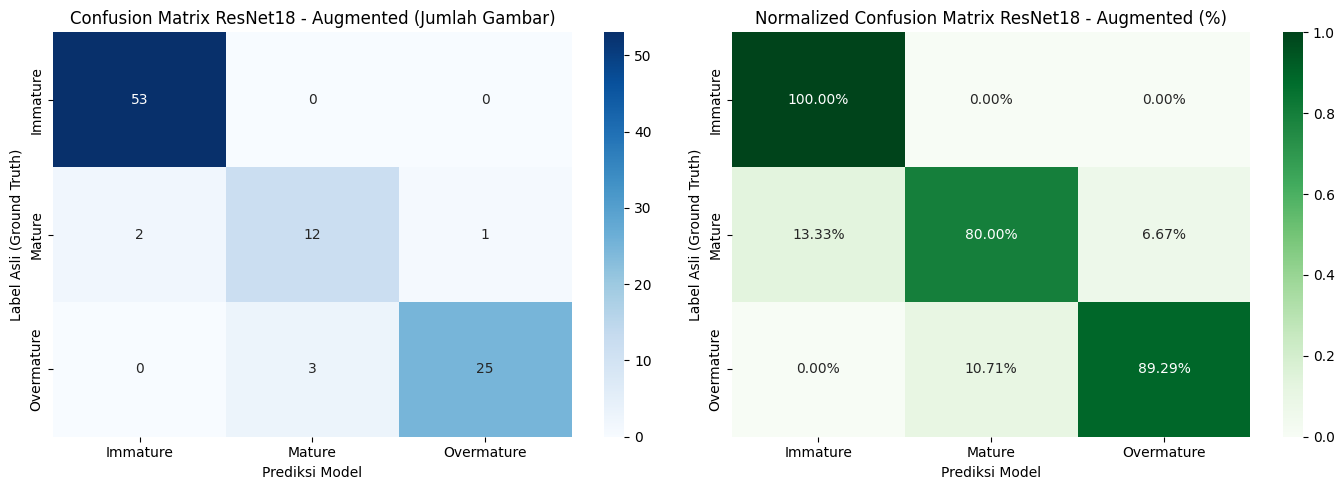

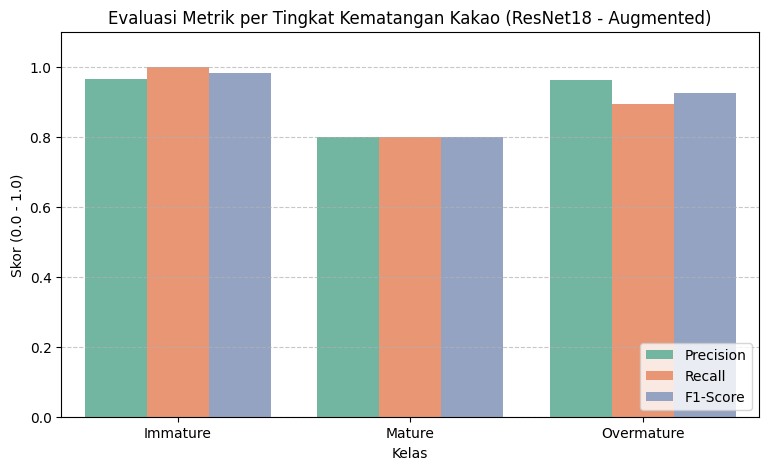

In [ ]:
eval_resnet_aug = evaluate_model(model_resnet_aug, best_path_resnet_aug, "ResNet18")

### Langkah 8 - Training ulang Model 2: EfficientNet-B0 (dataset augmentasi)
---
Sama seperti ResNet18, konfigurasi dipertahankan dan hanya data train yang diganti dengan dataset hasil augmentasi.

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 88.1MB/s]


VALIDASI DATASET TRAINING
Folder train : /content/dataset_augmented/train
Sampler      : RandomSampler
Kelas          Total  Original   Augmentasi (aug_)
Immature         157       157                   0
Mature           157        46                 111
Overmature       157        82                  75
------------------------------------------------------------------
✅ Membaca folder dataset_augmented/train
✅ Berisi gambar hasil augmentasi (186 file aug_)
✅ Jumlah tiap kelas seimbang
✅ Tidak memakai WeightedRandomSampler

[EfficientNet-B0] TRAINING DIMULAI pada dataset AUGMENTASI (285 original + 186 augmentasi)

[EfficientNet-B0 | AUG] Epoch [1/20] Train Loss: 0.5140 | Train Acc: 0.8110 | Val Loss: 0.1944 | Val Acc: 0.9474
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.9474)
[EfficientNet-B0 | AUG] Epoch [2/20] Train Loss: 0.0922 | Train Acc: 0.9703 | Val Loss: 0.1245 | Val Acc: 0.9579
  --> Checkpoint disimpan! (Val Acc Meningkat: 0.9579)
[EfficientNet-B0 | AUG] Epoch [3/20] Tra

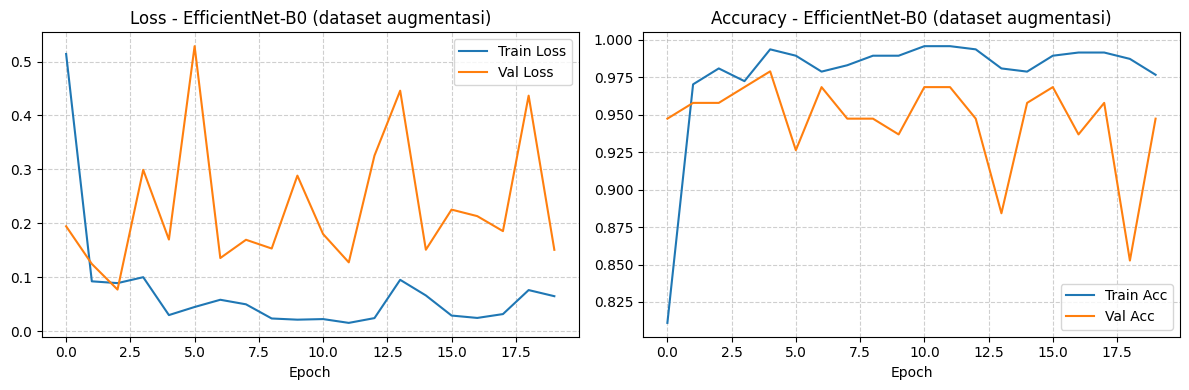

In [ ]:
set_seed()

model_effnet_aug = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
model_effnet_aug.classifier[1] = nn.Linear(model_effnet_aug.classifier[1].in_features, NUM_CLASSES)

best_path_effnet_aug = os.path.join(CHECKPOINT_DIR, "best_efficientnet_b0_cocoa_augmented.pth")

model_effnet_aug, history_effnet_aug = train_model(
    model_effnet_aug, "EfficientNet-B0", best_path_effnet_aug, epochs=EPOCHS, lr=LR
)
plot_history(history_effnet_aug, "EfficientNet-B0")

### Langkah 9 - Simpan checkpoint EfficientNet-B0 (augmented) ke Google Drive
---

In [ ]:
save_to_drive(best_path_effnet_aug)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Berhasil! best_efficientnet_b0_cocoa_augmented.pth disimpan ke Google Drive:
   /content/drive/MyDrive/Matkul AI/Cocoa/Checkpoints/best_efficientnet_b0_cocoa_augmented.pth


### Langkah 10 - Evaluasi EfficientNet-B0 (augmented) pada data test asli
---

VALIDASI CHECKPOINT: best_efficientnet_b0_cocoa_augmented.pth
Tipe dataset train  : augmented_balanced
Folder train        : /content/dataset_augmented/train
Jumlah per kelas    : {'Immature': 157, 'Mature': 157, 'Overmature': 157}
Gambar original     : 285
Gambar augmentasi   : 186
✅ Model ini dilatih pada dataset hasil augmentasi (balanced)
Model EfficientNet-B0 dimuat dari Epoch 5 (Val Acc: 0.9789)

   CLASSIFICATION REPORT (EfficientNet-B0 - Dataset Augmentasi)
              precision    recall  f1-score   support

    Immature     0.9811    0.9811    0.9811        53
      Mature     0.9286    0.8667    0.8966        15
  Overmature     0.9655    1.0000    0.9825        28

    accuracy                         0.9688        96
   macro avg     0.9584    0.9493    0.9534        96
weighted avg     0.9684    0.9688    0.9683        96



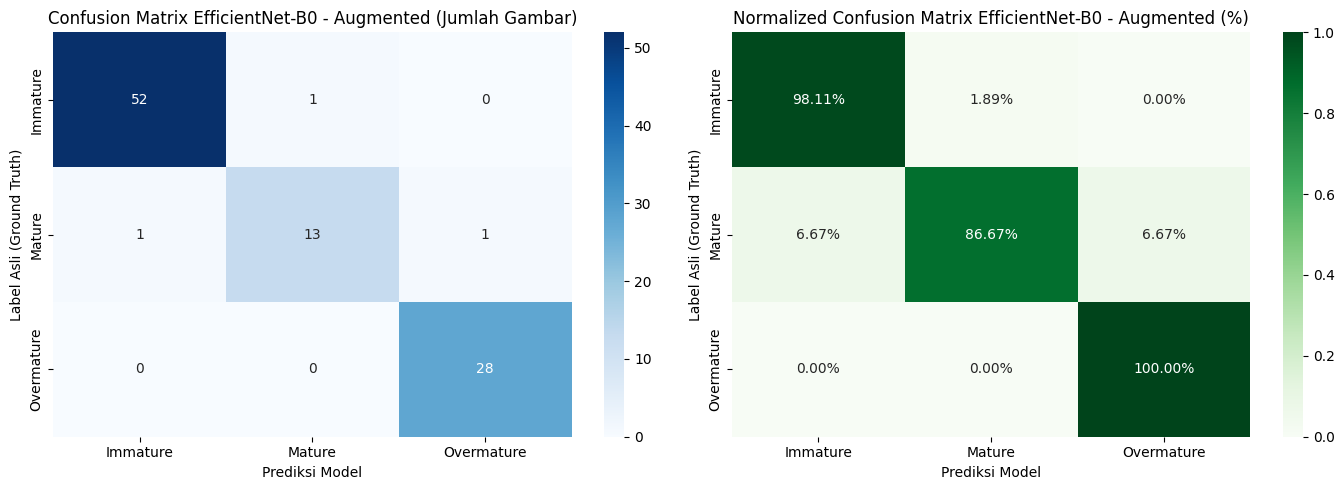

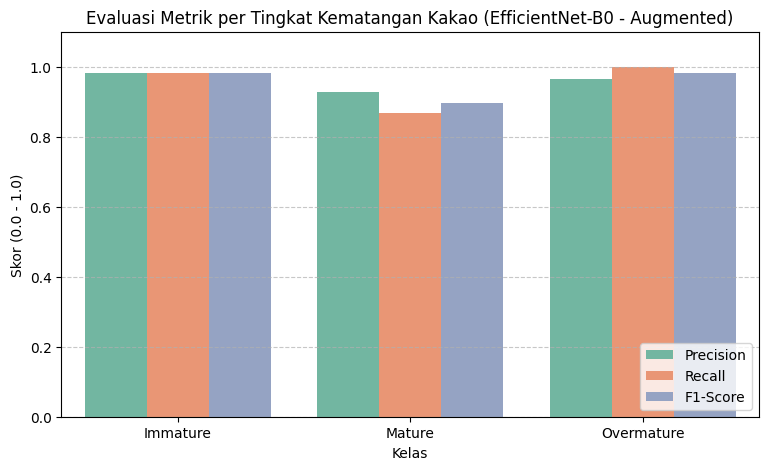

In [ ]:
eval_effnet_aug = evaluate_model(model_effnet_aug, best_path_effnet_aug, "EfficientNet-B0")

### Langkah 11 - Ringkasan bukti dataset augmentasi yang dipakai kedua model
---
Tabel ringkas yang bisa ditunjukkan ke dosen pembimbing: kedua model dilatih dengan dataset yang sama, yaitu train hasil augmentasi yang seimbang.

In [ ]:
proof_rows = []
for name, path in [("ResNet18", best_path_resnet_aug), ("EfficientNet-B0", best_path_effnet_aug)]:
    ck = torch.load(path, map_location="cpu")
    row = {
        "Model": name,
        "Tipe dataset train": ck["dataset_type"],
        "Folder train": os.path.relpath(ck["train_dir"]),
        "Original": ck["n_original_images"],
        "Augmentasi": ck["n_augmented_images"],
        "Total train": ck["n_original_images"] + ck["n_augmented_images"],
        "Best epoch": ck["epoch"],
        "Best Val Acc": round(ck["val_acc"], 4),
    }
    row.update({f"n {k}": v for k, v in ck["train_class_counts"].items()})
    proof_rows.append(row)

display(pd.DataFrame(proof_rows).set_index("Model").T)

Model,ResNet18,EfficientNet-B0
Tipe dataset train,augmented_balanced,augmented_balanced
Folder train,dataset_augmented/train,dataset_augmented/train
Original,285,285
Augmentasi,186,186
Total train,471,471
Best epoch,9,5
Best Val Acc,0.9368,0.9789
n Immature,157,157
n Mature,157,157
n Overmature,157,157


### Langkah 12 - Perbandingan hasil: sebelum (data asli + sampler) vs sesudah (dataset augmentasi)
---
Perbandingan pada **test set yang sama** (data asli, tidak diaugmentasi). Jika hasil training lama masih ada di sesi Colab (variabel `all_preds`, `all_preds_effnet`), nilainya dihitung ulang langsung; jika tidak, dipakai angka dari output notebook sebelumnya.

Catatan: test set berukuran kecil (96 gambar, Mature hanya 15), sehingga selisih 1–2 gambar sudah mengubah metrik cukup besar. Gunakan selisih kecil sebagai indikasi, bukan bukti pasti.

,Model,Dataset train,Accuracy,Macro F1,Recall Mature
0,ResNet18,Asli + WeightedRandomSampler *,0.9271,0.8955,0.9333
1,EfficientNet-B0,Asli + WeightedRandomSampler *,0.9375,0.9053,0.8000
2,ResNet18,Augmentasi (balanced),0.9375,0.9025,0.8000
3,EfficientNet-B0,Augmentasi (balanced),0.9688,0.9534,0.8667


* = angka diambil dari output notebook sebelumnya (variabel sesi lama tidak tersedia).


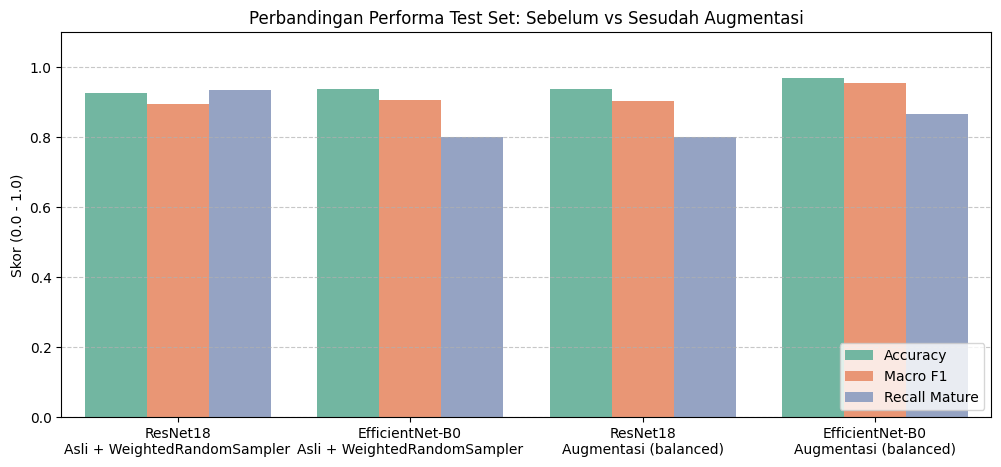

In [ ]:
mature_idx = class_names_aug.index("Mature")

def summarize(model_name, dataset_desc, y_true, y_pred):
    rec = precision_recall_fscore_support(y_true, y_pred, average=None, zero_division=0)[1]
    return {
        "Model": model_name,
        "Dataset train": dataset_desc,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall Mature": rec[mature_idx],
    }

BEFORE = "Asli + WeightedRandomSampler"
AFTER  = "Augmentasi (balanced)"
rows = []

# ---- Sebelum (hitung dari variabel sesi lama bila ada, jika tidak pakai angka dari output notebook) ----
if "all_preds" in globals() and "all_labels" in globals():
    rows.append(summarize("ResNet18", BEFORE, all_labels, all_preds))
else:
    rows.append({"Model": "ResNet18", "Dataset train": BEFORE + " *", "Accuracy": 0.9271, "Macro F1": 0.8955, "Recall Mature": 0.9333})

if "all_preds_effnet" in globals() and "all_labels_effnet" in globals():
    rows.append(summarize("EfficientNet-B0", BEFORE, all_labels_effnet, all_preds_effnet))
else:
    rows.append({"Model": "EfficientNet-B0", "Dataset train": BEFORE + " *", "Accuracy": 0.9375, "Macro F1": 0.9053, "Recall Mature": 0.8000})

# ---- Sesudah ----
rows.append(summarize("ResNet18", AFTER, eval_resnet_aug["y_true"], eval_resnet_aug["y_pred"]))
rows.append(summarize("EfficientNet-B0", AFTER, eval_effnet_aug["y_true"], eval_effnet_aug["y_pred"]))

df_cmp = pd.DataFrame(rows)
display(df_cmp.round(4))
if df_cmp["Dataset train"].str.contains(r"\*").any():
    print("* = angka diambil dari output notebook sebelumnya (variabel sesi lama tidak tersedia).")

df_plot = df_cmp.melt(id_vars=["Model", "Dataset train"], value_vars=["Accuracy", "Macro F1", "Recall Mature"],
                      var_name="Metrik", value_name="Nilai")
df_plot["Kelompok"] = df_plot["Model"] + "\n" + df_plot["Dataset train"].str.replace(" *", "", regex=False)

plt.figure(figsize=(12, 5))
sns.barplot(data=df_plot, x="Kelompok", y="Nilai", hue="Metrik", palette="Set2")
plt.title("Perbandingan Performa Test Set: Sebelum vs Sesudah Augmentasi")
plt.ylim(0, 1.1); plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.xlabel(""); plt.ylabel("Skor (0.0 - 1.0)")
plt.legend(loc="lower right"); plt.show()

### Langkah 13 - Evaluasi Soft-Voting Ensemble ResNet18 + EfficientNet-B0
---

Bagian ini menambahkan evaluasi ensemble yang sebelumnya belum dihitung pada notebook. Kedua model dimuat dari checkpoint dataset augmentasi. Bobot `alpha` dipilih menggunakan **validation set saja** berdasarkan macro-F1, kemudian bobot tersebut dikunci untuk evaluasi test set. Test set tidak digunakan untuk memilih bobot.

Rumus: `P_ensemble = alpha * P_ResNet18 + (1 - alpha) * P_EfficientNetB0`. Ensemble tidak diasumsikan lebih baik; hasilnya harus dibandingkan dengan masing-masing model. Jalankan setelah seluruh cell training dan evaluasi model augmented berhasil.


In [ ]:
# ============================================================
# Soft-voting ensemble: validation-only weight selection
# ============================================================
import json
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Pastikan kedua checkpoint benar-benar milik eksperimen augmented yang sama.
ckpt_resnet_ens = torch.load(best_path_resnet_aug, map_location=device)
ckpt_effnet_ens = torch.load(best_path_effnet_aug, map_location=device)

assert ckpt_resnet_ens.get("dataset_type") == "augmented_balanced"
assert ckpt_effnet_ens.get("dataset_type") == "augmented_balanced"
assert ckpt_resnet_ens.get("class_names") == ckpt_effnet_ens.get("class_names")
assert list(ckpt_resnet_ens.get("class_names", [])) == list(class_names_aug)

model_resnet_aug.load_state_dict(ckpt_resnet_ens["model_state_dict"])
model_effnet_aug.load_state_dict(ckpt_effnet_ens["model_state_dict"])
model_resnet_aug.to(device).eval()
model_effnet_aug.to(device).eval()


def predict_probabilities(model, loader):
    """Return softmax probabilities and ground-truth labels in loader order."""
    model.eval()
    probs_all, labels_all = [], []
    with torch.inference_mode():
        for images, labels in loader:
            logits = model(images.to(device))
            probs_all.append(torch.softmax(logits, dim=1).cpu().numpy())
            labels_all.append(labels.numpy())
    return np.concatenate(probs_all, axis=0), np.concatenate(labels_all, axis=0)


# Predict on validation first; this is the only split used to choose alpha.
val_prob_res, y_val_res = predict_probabilities(model_resnet_aug, val_loader_aug)
val_prob_eff, y_val_eff = predict_probabilities(model_effnet_aug, val_loader_aug)
assert np.array_equal(y_val_res, y_val_eff), "Urutan label validation kedua model berbeda."

# Grid search coarse weights. A tie is resolved by choosing the value closest to 0.5.
alpha_grid = np.linspace(0.0, 1.0, 21)
val_scores = []
for alpha in alpha_grid:
    val_ensemble_prob = alpha * val_prob_res + (1.0 - alpha) * val_prob_eff
    val_pred = val_ensemble_prob.argmax(axis=1)
    val_scores.append(f1_score(y_val_res, val_pred, average="macro", zero_division=0))

best_val_score = max(val_scores)
best_candidates = [
    float(a) for a, score in zip(alpha_grid, val_scores)
    if np.isclose(score, best_val_score)
]
best_alpha = min(best_candidates, key=lambda a: abs(a - 0.5))

print("Pemilihan bobot hanya menggunakan validation set")
print(f"Best alpha ResNet18       : {best_alpha:.2f}")
print(f"Bobot EfficientNet-B0     : {1.0 - best_alpha:.2f}")
print(f"Validation macro-F1       : {best_val_score:.4f}")

# Setelah alpha dikunci, evaluasi test set tepat satu kali.
test_prob_res, y_test_res = predict_probabilities(model_resnet_aug, test_loader_aug)
test_prob_eff, y_test_eff = predict_probabilities(model_effnet_aug, test_loader_aug)
assert np.array_equal(y_test_res, y_test_eff), "Urutan label test kedua model berbeda."

prob_equal = 0.5 * test_prob_res + 0.5 * test_prob_eff
prob_tuned = best_alpha * test_prob_res + (1.0 - best_alpha) * test_prob_eff

predictions = {
    "ResNet18": test_prob_res.argmax(axis=1),
    "EfficientNet-B0": test_prob_eff.argmax(axis=1),
    "Soft Voting (alpha=0.50)": prob_equal.argmax(axis=1),
    f"Soft Voting (alpha={best_alpha:.2f})": prob_tuned.argmax(axis=1),
}

mature_idx = class_names_aug.index("Mature")
ensemble_rows = []
for model_name, y_pred in predictions.items():
    per_class_recall = precision_recall_fscore_support(
        y_test_res, y_pred, average=None, zero_division=0
    )[1]
    ensemble_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_res, y_pred),
        "Macro F1": f1_score(y_test_res, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test_res, y_pred, average="weighted", zero_division=0),
        "Recall Mature": per_class_recall[mature_idx],
    })

df_ensemble_test = pd.DataFrame(ensemble_rows).set_index("Model")
display(df_ensemble_test.round(4))

chosen_name = f"Soft Voting (alpha={best_alpha:.2f})"
y_pred_ensemble = predictions[chosen_name]
print("\nClassification report - ensemble dengan alpha hasil validation:")
print(classification_report(
    y_test_res, y_pred_ensemble,
    target_names=class_names_aug, digits=4, zero_division=0
))

cm_ensemble = confusion_matrix(y_test_res, y_pred_ensemble)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_ensemble, annot=True, fmt="d", cmap="Greens",
    xticklabels=class_names_aug, yticklabels=class_names_aug
)
plt.title(f"Confusion Matrix - {chosen_name}")
plt.xlabel("Prediksi")
plt.ylabel("Label aktual")
plt.tight_layout()
plt.show()

# Simpan metadata konfigurasi agar backend memakai urutan kelas dan bobot yang sama.
ensemble_config = {
    "ensemble_method": "soft_voting",
    "alpha_resnet18": float(best_alpha),
    "alpha_efficientnet_b0": float(1.0 - best_alpha),
    "class_names": list(class_names_aug),
    "input_size": [224, 224],
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "resnet18_checkpoint": os.path.basename(best_path_resnet_aug),
    "efficientnet_b0_checkpoint": os.path.basename(best_path_effnet_aug),
    "weight_selection_split": "validation",
    "final_evaluation_split": "test",
}
with open("ensemble_config.json", "w", encoding="utf-8") as f:
    json.dump(ensemble_config, f, ensure_ascii=False, indent=2)

print("\nKonfigurasi ensemble disimpan ke ensemble_config.json")
print("Catatan: ensemble hanya layak dipilih bila metrik test dan error per kelasnya mendukung.")
